In [1]:
pip install ultralytics

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.1/1.1 MB 17.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 363.4/363.4 MB 4.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 664.8/664.8 MB 2.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 211.5/211.5 MB 7.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.3/56.3 MB 12.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 127.9/127.9 MB 12.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 207.5/207.5 MB 3.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 21.1/21.1 MB 3.6 MB/s eta 0:00:00
  Attempting uninstall: nvidia-nvjitlink-cu12
    Found existing installation: nvidia-nvjitlink-cu12 12.8.93
    Uninstalling nvidia-nvjitlink-cu12-12.8.93:
      Successfully uninstalled nvidia-nvjitlink-cu12-12.8.93
  Attempting uninstall: nvidia-curand-cu12
    Found existing installation: nvidia-curand-cu12 10.3.9.90
    Uninstalling nvidia-curand-cu12-10.3.9

In [2]:
import os
from glob import glob
from tqdm.notebook import tqdm
from ultralytics import YOLO
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix
import pandas as pd
import random
import torch
import shutil
from pathlib import Path
from tqdm.auto import tqdm
import yaml

Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.


In [3]:
!cp -r /kaggle/input/rasoul-binary-aabb/dataset /kaggle/working/

In [4]:
# Set the seed value
SEED = 42  

# Python’s built-in random module
random.seed(SEED)

# NumPy
np.random.seed(SEED)

# PyTorch
torch.manual_seed(SEED)
torch.cuda.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

# Ensure deterministic behavior in PyTorch
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

# Set PYTHONHASHSEED to ensure consistent behavior in hash-based operations
os.environ["PYTHONHASHSEED"] = str(SEED)

In [5]:
# --- 1. SETUP AND PATH DEFINITIONS ---
# --- MODIFIED: Using pathlib.Path to prevent AttributeErrors ---
dataset_yaml_path = Path("/kaggle/working/dataset.yaml")
weights_dir = Path('/kaggle/input/yolo-binary-detection-weights/B-AABBWeights')
output_dir_data = Path("/kaggle/working/data_outputs")
output_dir_plots = Path("/kaggle/working/myplots")
output_dir_final_runs = Path("/kaggle/working/optimal_runs")

# Create all necessary output directories
os.makedirs(output_dir_data, exist_ok=True)
os.makedirs(output_dir_plots, exist_ok=True)
os.makedirs(output_dir_final_runs, exist_ok=True)
os.makedirs(output_dir_plots / "ConfMats", exist_ok=True)

In [6]:
# Generating yaml file
# Define YOLO dataset structure
data = {
    'train': '/kaggle/working/dataset/images/train',
    'val': '/kaggle/working/dataset/images/val',
    'test': '/kaggle/working/dataset/images/test',
    'nc': 1,  # Number of classes
    'names': ['ICH']  # Class names
}

# Save YAML file
with open(dataset_yaml_path, 'w') as file:
    yaml.dump(data, file, default_flow_style=False)

print(f"YAML file saved at: {dataset_yaml_path}")

YAML file saved at: /kaggle/working/dataset.yaml


In [7]:
def organize_confusion_matrices(source_dir: Path, dest_dir: Path):
    """
    Finds confusion matrices in subdirectories, renames them by their parent
    folder's name, and copies them to a destination folder.
    """
    # 1. Create the destination folder if it doesn't exist
    dest_dir.mkdir(parents=True, exist_ok=True)
    
    # 2. Find all 'confusion_matrix.png' files within the source subdirectories
    source_files = list(source_dir.glob('*/confusion_matrix.png'))
    
    if not source_files:
        print(f"⚠️ Warning: No 'confusion_matrix.png' files found under '{source_dir}'")
        return

    print(f"Found {len(source_files)} confusion matrices. Copying to '{dest_dir}'...")
    
    # 3. Loop through the files with a progress bar, copy, and rename
    for source_path in tqdm(source_files, desc="Copying Matrices"):
        try:
            # Extract the model name from the parent directory's name
            model_name = source_path.parent.name
            
            # Define the new path for the copied file
            dest_path = dest_dir / f"{model_name}_confusion_matrix.png"
            
            # Copy the file
            shutil.copy(source_path, dest_path)
            
        except Exception as e:
            print(f"❌ Error processing {source_path.name}: {e}")

    print(f"\n✅ Copying complete.")

In [8]:
# --- 2. MAIN THRESHOLD-TUNING LOOP ---
# Collect model paths
model_paths = list(weights_dir.glob('*.pt'))

output_results = []
pbar = tqdm(model_paths, desc="Processing models")

for model_path in pbar:
    model_name = os.path.basename(model_path).replace('.pt', '')
    pbar.set_description(f"Tuning {model_name}")
    
    model = YOLO(model_path)
    
    thresholds = np.arange(0.05, 1.0, 0.05)
    
    best_f1 = -1.0
    best_metrics_at_thresh = {}
    best_run_dir = None # <-- Variable to store the path to the best run's directory

    for t in tqdm(thresholds, desc=f"Threshold sweep for {model_name}", leave=False):
        # Run official validation at the current threshold 't'
        # Let YOLO manage temp directories by not setting project/name here
        metrics = model.val(
            data=str(dataset_yaml_path),
            split='val',
            conf=t,
            iou=0.5, 
            verbose=False,
            seed=SEED,
            project='/kaggle/working/tuning_runs',      # Main directory for all sweeps
            name=f'{model_name}_conf_{t:.3f}',         # Specific, traceable name for this run
            exist_ok=True,
            device=0
        )
        
        current_f1 = metrics.box.f1[0]
        
        # If this threshold gives a better F1-score, save its metrics AND its directory path
        if current_f1 > best_f1:
            best_f1 = current_f1
            best_run_dir = metrics.save_dir # <-- Save the path to the entire results folder
            best_metrics_at_thresh = {
                'model': model_name,
                'best_threshold': t,
                'f1': current_f1,
                'precision': metrics.box.p[0],
                'recall': metrics.box.r[0],
                'mAP@0.5': metrics.box.map50,
                'mAP@0.5:0.95': metrics.box.map,
                'run_dir': str(best_run_dir) # <-- Add the path to the results dictionary
            }

    if best_metrics_at_thresh:
        output_results.append(best_metrics_at_thresh)
    else:
        print(f"Warning: No valid metrics found for {model_name}.")

pbar.close()

Processing models:   0%|          | 0/9 [00:00<?, ?it/s]

Threshold sweep for yolov8m:   0%|          | 0/19 [00:00<?, ?it/s]

Ultralytics 8.3.199 🚀 Python-3.11.11 torch-2.5.1+cu124 CUDA:0 (Tesla T4, 15095MiB)
Model summary (fused): 92 layers, 25,840,339 parameters, 0 gradients, 78.7 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1093.4±333.0 MB/s, size: 36.7 KB)
val: Scanning /kaggle/working/dataset/labels/val... 1990 images, 1568 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1990/1990 1.6Kit/s 1.3s
val: New cache created: /kaggle/working/dataset/labels/val.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 125/125 2.8it/s 43.9s


/usr/local/lib/python3.11/dist-packages/matplotlib/colors.py:721: RuntimeWarning: invalid value encountered in less
  xa[xa < 0] = -1
/usr/local/lib/python3.11/dist-packages/matplotlib/colors.py:721: RuntimeWarning: invalid value encountered in less
  xa[xa < 0] = -1


                   all       1990        823      0.697      0.469      0.604       0.39
Speed: 0.4ms preprocess, 19.8ms inference, 0.0ms loss, 0.4ms postprocess per image
Results saved to /kaggle/working/tuning_runs/yolov8m_conf_0.050
Ultralytics 8.3.199 🚀 Python-3.11.11 torch-2.5.1+cu124 CUDA:0 (Tesla T4, 15095MiB)
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1076.1±462.3 MB/s, size: 34.0 KB)
val: Scanning /kaggle/working/dataset/labels/val.cache... 1990 images, 1568 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1990/1990 3.9Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 125/125 2.8it/s 44.7s


...

                   all       1990        823      0.963      0.253      0.612      0.475
Speed: 0.5ms preprocess, 3.8ms inference, 0.0ms loss, 0.2ms postprocess per image
Results saved to /kaggle/working/tuning_runs/yolov8n_conf_0.850
Ultralytics 8.3.199 🚀 Python-3.11.11 torch-2.5.1+cu124 CUDA:0 (Tesla T4, 15095MiB)
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1150.5±429.9 MB/s, size: 33.3 KB)
val: Scanning /kaggle/working/dataset/labels/val.cache... 1990 images, 1568 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1990/1990 4.1Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 125/125 12.0it/s 10.4s


/usr/local/lib/python3.11/dist-packages/matplotlib/colors.py:721: RuntimeWarning: invalid value encountered in less
  xa[xa < 0] = -1
/usr/local/lib/python3.11/dist-packages/matplotlib/colors.py:721: RuntimeWarning: invalid value encountered in less
  xa[xa < 0] = -1


                   all       1990        823          1      0.106      0.553      0.456
Speed: 0.4ms preprocess, 3.9ms inference, 0.0ms loss, 0.2ms postprocess per image
Results saved to /kaggle/working/tuning_runs/yolov8n_conf_0.900
Ultralytics 8.3.199 🚀 Python-3.11.11 torch-2.5.1+cu124 CUDA:0 (Tesla T4, 15095MiB)
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1060.4±776.2 MB/s, size: 29.1 KB)
val: Scanning /kaggle/working/dataset/labels/val.cache... 1990 images, 1568 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1990/1990 4.2Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 125/125 12.2it/s 10.3s


/usr/local/lib/python3.11/dist-packages/matplotlib/colors.py:721: RuntimeWarning: invalid value encountered in less
  xa[xa < 0] = -1
/usr/local/lib/python3.11/dist-packages/matplotlib/colors.py:721: RuntimeWarning: invalid value encountered in less
  xa[xa < 0] = -1


                   all       1990        823          1    0.00365      0.502      0.401
Speed: 0.7ms preprocess, 3.9ms inference, 0.0ms loss, 0.1ms postprocess per image
Results saved to /kaggle/working/tuning_runs/yolov8n_conf_0.950


In [9]:
# --- 3. DATA SAVING AND ORGANIZATION ---
if not output_results:
    print("No results were generated. Exiting.")
else:
    df = pd.DataFrame(output_results)
    df.to_csv(os.path.join(output_dir_data, 'model_performance_summary.csv'), index=False)
    
    print("\n--- Best Model Performance Metrics (F1-Optimized on Val Set) ---")
    print(df[['model', 'best_threshold', 'f1', 'precision', 'recall', 'mAP@0.5']])
    
    # --- Final Step: Copy the best run directory for each model ---
    print(f"\n--- Copying optimal run data to {output_dir_final_runs} ---")
    for idx, row in df.iterrows():
        model_name = row['model']
        source_dir = row['run_dir']
        dest_dir = os.path.join(output_dir_final_runs, model_name)
        
        if os.path.exists(source_dir):
            # Remove the destination directory if it already exists to ensure a fresh copy
            if os.path.exists(dest_dir):
                shutil.rmtree(dest_dir)
            shutil.copytree(source_dir, dest_dir)
            print(f"Copied best run for {model_name} to {dest_dir}")
        else:
            print(f"Warning: Source directory not found for {model_name} at {source_dir}")

    print(f"\n✅ Tuning complete. Final results folders saved to '{output_dir_final_runs}'")


--- Best Model Performance Metrics (F1-Optimized on Val Set) ---
     model  best_threshold        f1  precision    recall   mAP@0.5
0  yolov8m            0.40  0.562044   0.703839  0.467801  0.622917
1  yolo12n            0.05  0.557154   0.740241  0.446676  0.577754
2  yolo11n            0.65  0.559390   0.783428  0.434994  0.624816
3  yolo12m            0.50  0.550486   0.715953  0.447145  0.603197
4  yolo11s            0.75  0.546875   0.765864  0.425273  0.615838
5  yolo11m            0.60  0.550186   0.708812  0.449575  0.611600
6  yolov8s            0.50  0.567365   0.738791  0.460510  0.624372
7  yolo12s            0.05  0.577713   0.731112  0.477521  0.574067
8  yolov8n            0.25  0.584752   0.748106  0.479951  0.648330

--- Copying optimal run data to /kaggle/working/optimal_runs ---
Copied best run for yolov8m to /kaggle/working/optimal_runs/yolov8m
Copied best run for yolo12n to /kaggle/working/optimal_runs/yolo12n
Copied best run for yolo11n to /kaggle/working/optim

In [10]:
models = [
    "yolov8n", "yolov8s", "yolov8m",
    "yolo11n", "yolo11s", "yolo11m",
    "yolo12n", "yolo12s", "yolo12m"
]

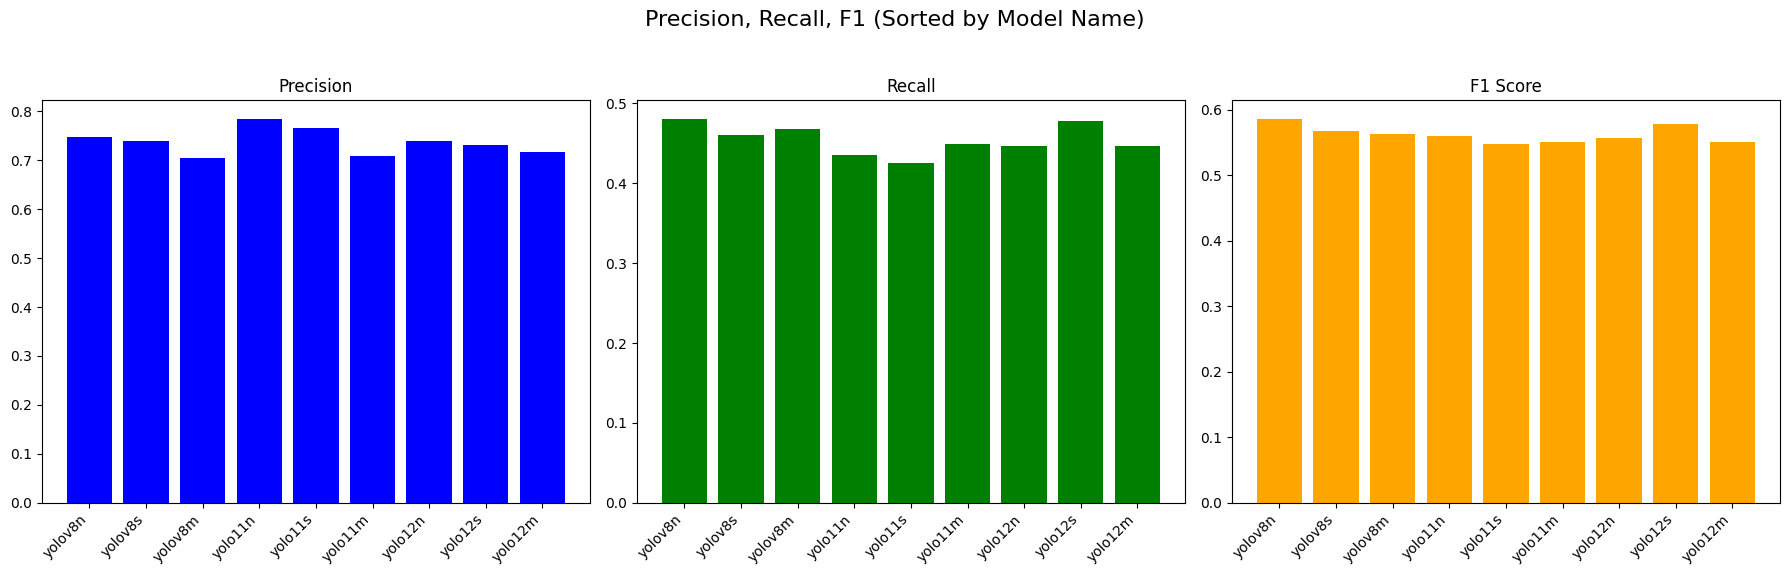

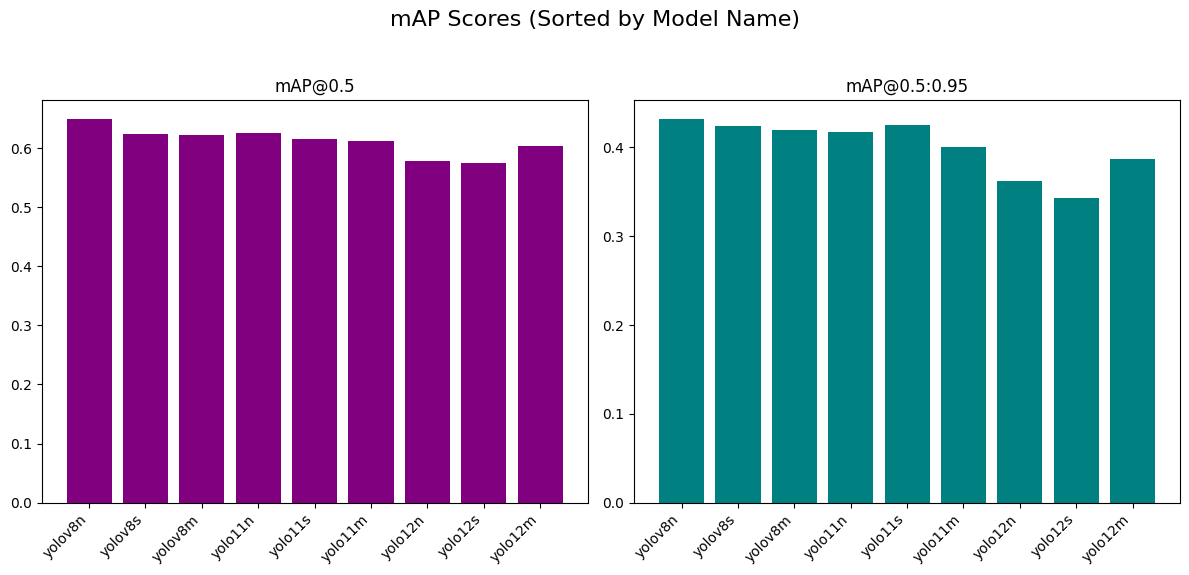

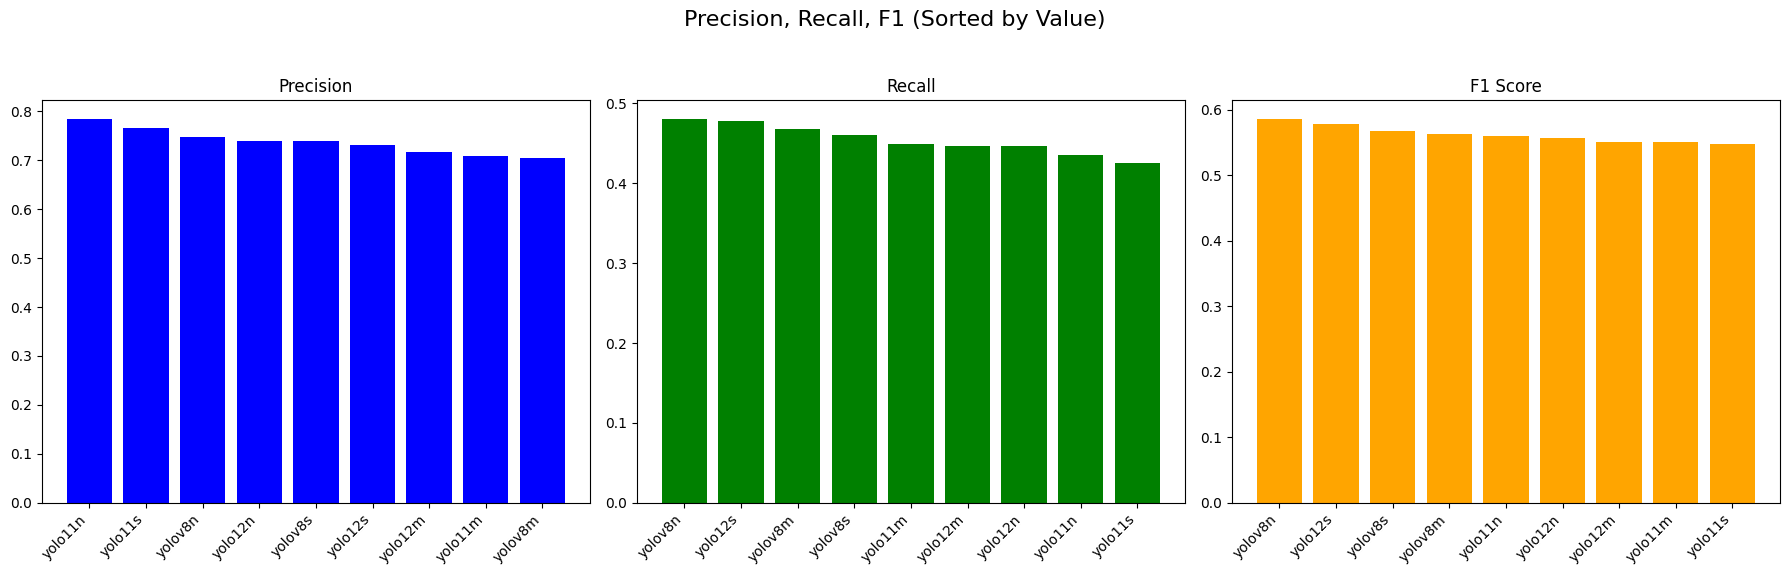

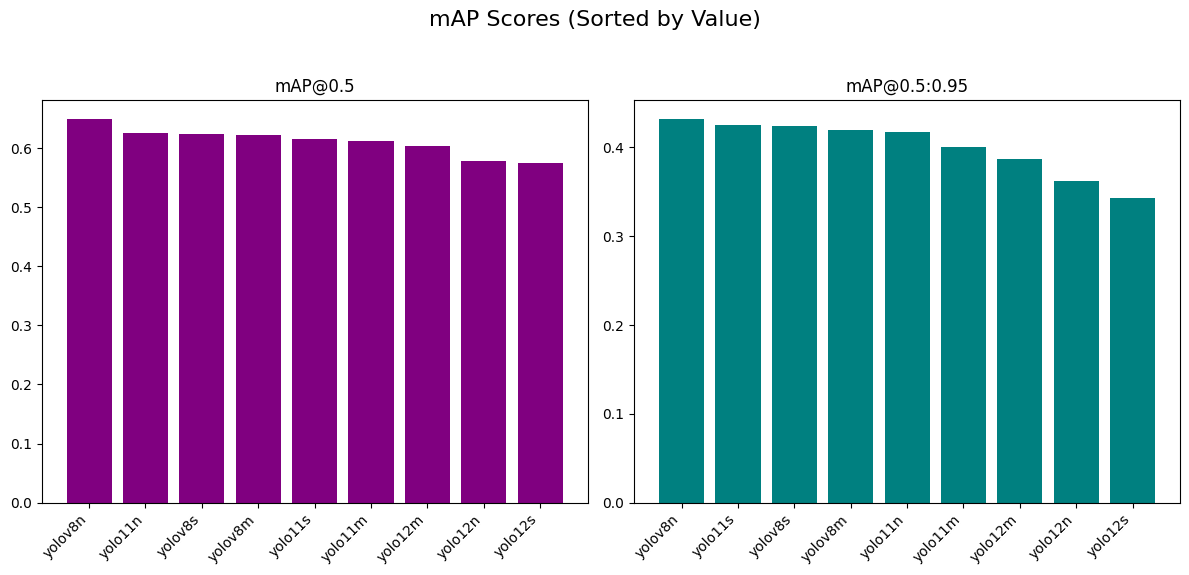

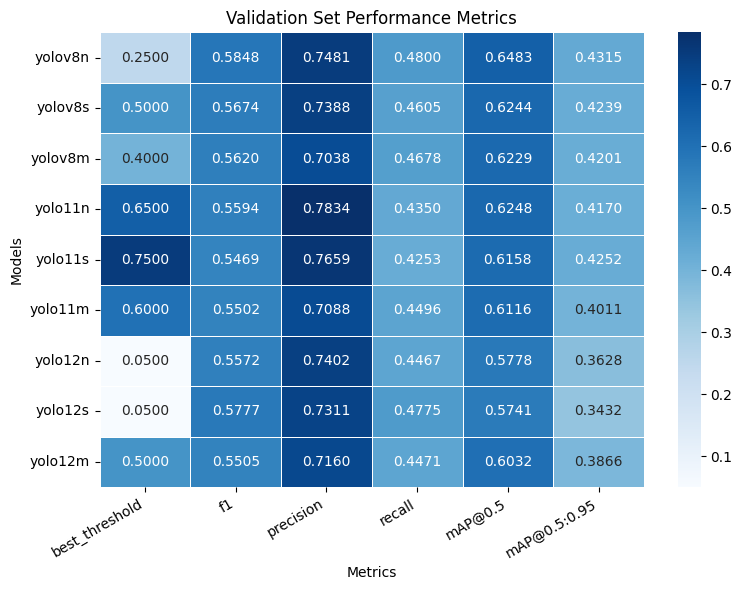

Found 9 confusion matrices. Copying to '/kaggle/working/myplots/ConfMats'...


Copying Matrices:   0%|          | 0/9 [00:00<?, ?it/s]


✅ Copying complete.

Zipping output files...
✅ All tasks complete.


In [11]:
# --- 4. PLOTTING ---
if not output_results:
    print("Skipping plotting as no results were generated.")
else:
    models_order = ["yolov8n", "yolov8s", "yolov8m", "yolo11n", "yolo11s", "yolo11m", "yolo12n", "yolo12s", "yolo12m"]
    df['model'] = pd.Categorical(df['model'], categories=models_order, ordered=True)
    df_ordered = df.sort_values('model')

    # --- Plots Sorted by Model Name ---
    fig, axes = plt.subplots(1, 3, figsize=(18, 6))
    fig.suptitle('Precision, Recall, F1 (Sorted by Model Name)', fontsize=16)
    
    x = np.arange(len(df_ordered))
    axes[0].bar(x, df_ordered['precision'], color='blue')
    axes[0].set_title('Precision')
    axes[0].set_xticks(x)
    axes[0].set_xticklabels(df_ordered['model'], rotation=45, ha='right')
    
    axes[1].bar(x, df_ordered['recall'], color='green')
    axes[1].set_title('Recall')
    axes[1].set_xticks(x)
    axes[1].set_xticklabels(df_ordered['model'], rotation=45, ha='right')
    
    axes[2].bar(x, df_ordered['f1'], color='orange')
    axes[2].set_title('F1 Score')
    axes[2].set_xticks(x)
    axes[2].set_xticklabels(df_ordered['model'], rotation=45, ha='right')
    plt.tight_layout(rect=[0, 0.03, 1, 0.95])
    plt.savefig(output_dir_plots / "Val_PRF_byName.png")
    plt.show()

    fig, axes = plt.subplots(1, 2, figsize=(12, 6))
    fig.suptitle('mAP Scores (Sorted by Model Name)', fontsize=16)
    axes[0].bar(x, df_ordered['mAP@0.5'], color='purple')
    axes[0].set_title('mAP@0.5')
    axes[0].set_xticks(x)
    axes[0].set_xticklabels(df_ordered['model'], rotation=45, ha='right')
    
    axes[1].bar(x, df_ordered['mAP@0.5:0.95'], color='teal')
    axes[1].set_title('mAP@0.5:0.95')
    axes[1].set_xticks(x)
    axes[1].set_xticklabels(df_ordered['model'], rotation=45, ha='right')
    plt.tight_layout(rect=[0, 0.03, 1, 0.95])
    plt.savefig(output_dir_plots / "Val_mAP_byName.png")
    plt.show()
    
    # --- NEW: Plots Sorted by Metric Value ---
    fig, axes = plt.subplots(1, 3, figsize=(18, 6))
    fig.suptitle('Precision, Recall, F1 (Sorted by Value)', fontsize=16)

    # Precision (Sorted)
    df_p = df.sort_values(by='precision', ascending=False)
    x_p = np.arange(len(df_p))
    axes[0].bar(x_p, df_p['precision'], color='blue')
    axes[0].set_title('Precision')
    axes[0].set_xticks(x_p)
    axes[0].set_xticklabels(df_p['model'], rotation=45, ha='right')

    # Recall (Sorted)
    df_r = df.sort_values(by='recall', ascending=False)
    x_r = np.arange(len(df_r))
    axes[1].bar(x_r, df_r['recall'], color='green')
    axes[1].set_title('Recall')
    axes[1].set_xticks(x_r)
    axes[1].set_xticklabels(df_r['model'], rotation=45, ha='right')

    # F1 Score (Sorted)
    df_f = df.sort_values(by='f1', ascending=False)
    x_f = np.arange(len(df_f))
    axes[2].bar(x_f, df_f['f1'], color='orange')
    axes[2].set_title('F1 Score')
    axes[2].set_xticks(x_f)
    axes[2].set_xticklabels(df_f['model'], rotation=45, ha='right')

    plt.tight_layout(rect=[0, 0.03, 1, 0.95])
    plt.savefig(output_dir_plots / "Val_PRF_byValue.png")
    plt.show()

    fig, axes = plt.subplots(1, 2, figsize=(12, 6))
    fig.suptitle('mAP Scores (Sorted by Value)', fontsize=16)

    # mAP@0.5 (Sorted)
    df_m50 = df.sort_values(by='mAP@0.5', ascending=False)
    x_m50 = np.arange(len(df_m50))
    axes[0].bar(x_m50, df_m50['mAP@0.5'], color='purple')
    axes[0].set_title('mAP@0.5')
    axes[0].set_xticks(x_m50)
    axes[0].set_xticklabels(df_m50['model'], rotation=45, ha='right')

    # mAP@0.5:0.95 (Sorted)
    df_m95 = df.sort_values(by='mAP@0.5:0.95', ascending=False)
    x_m95 = np.arange(len(df_m95))
    axes[1].bar(x_m95, df_m95['mAP@0.5:0.95'], color='teal')
    axes[1].set_title('mAP@0.5:0.95')
    axes[1].set_xticks(x_m95)
    axes[1].set_xticklabels(df_m95['model'], rotation=45, ha='right')

    plt.tight_layout(rect=[0, 0.03, 1, 0.95]); plt.savefig(output_dir_plots / "Val_mAP_byValue.png"); plt.show()
    
    # --- MODIFIED: Heatmap now includes the best_threshold column ---
    df_heatmap = df.set_index('model').drop(['run_dir'], axis=1).reindex(models_order)
    plt.figure(figsize=(8, 6)); sns.heatmap(df_heatmap, annot=True, fmt=".4f", cmap="Blues", linewidths=.5, cbar=True)
    plt.title("Validation Set Performance Metrics"); plt.xlabel("Metrics"); plt.ylabel("Models"); plt.xticks(rotation=30, ha="right"); plt.tight_layout()
    plt.savefig(output_dir_plots / "Val_Metrics_Heatmap.png"); plt.show()
    
    # Organize the saved confusion matrices from the best runs
    organize_confusion_matrices(output_dir_final_runs, output_dir_plots / "ConfMats")

    # Zip all results
    print("\nZipping output files...")
    shutil.make_archive(
        base_name="/kaggle/working/final_tuning_results",
        format='zip',
        root_dir=output_dir_final_runs.parent, 
        base_dir=output_dir_final_runs.name
    )
    shutil.make_archive(
        base_name="/kaggle/working/final_plots",
        format='zip',
        root_dir="/kaggle/working",
        base_dir="myplots"
    )
    
    print("✅ All tasks complete.")

In [12]:
!rm -rf /kaggle/working/dataset